# Systemy operacyjne - Laboratorium 5

In [41]:
import random
import pandas as pd
from typing import List, Tuple
from statistics import mean, stdev
from copy import deepcopy
import seaborn as sns
import matplotlib.pyplot as plt

### Parametry symulacji

In [42]:
CPU_NUM = 75 # Ilość procesorów -> N
PROCESS_NUM = 10_000 # Długość sekwencji
MAX_PROCESS_LOAD = 90 # Maksymalne obciążenie generowane przez 1 proces
CPU_SWITCH_COUNT = 5 # Ilość odpytań -> z
LOAD_THRESHOLD = 0.7 # Próg obciążenia -> p
MINIMUM_LOAD = 0.25 # Minimalne obciążenie -> r
MAX_EXECUTION_TIME = 150
STEAL_LOAD_RATIO = 0.2

### Procesor i Proces

In [43]:
class Process:
    def __init__(self, pid: int, load: float, execution_time: int):
        self.pid = pid
        self.load = load
        self.execution_time = execution_time
        self.time_remaining = execution_time

    def __repr__(self):
        return f"[pid: {self.pid}, load: {self.load}, execution time: {self.execution_time}]"


class CPU:
    def __init__(self):
        self.execution_queue = []
        self.completed = []

    def can_be_assigned(self, process: Process) -> bool:
        return process.load < 1 - sum([p.load for p in self.execution_queue])

    def get_load(self) -> float:
        if len(self.execution_queue) == 0:
            return 0
        else:
            return (sum([p.load for p in self.execution_queue]) / len(self.execution_queue)) * 0.01

    def proceed_execution(self):
        curr_load = 0
        for process in self.execution_queue:
            curr_load += process.load / 100
            process.time_remaining -= 1
            if process.time_remaining < 0:
                self.completed.append(process)
                self.execution_queue.remove(process)

    def __repr__(self):
        return f"[CPU: {self.execution_queue} COMPLETED: {self.completed}]"



### Generowanie sekwencji procesów

In [44]:
def gen_process_sequence(seq_len: int, max_process_load: int) -> List[Process]:
    seq = []
    for i in range(seq_len):
        random_load = random.randint(1, MAX_PROCESS_LOAD)
        exec_time = random.randint(1, MAX_EXECUTION_TIME)
        new_process = Process(
            pid=i,
            load=random_load,
            execution_time=exec_time
        )
        seq.append(new_process)

    return seq


def gen_cpu_seq(seq_len: int) -> List[CPU]:
    seq = []
    for i in range(seq_len):
        seq.append(CPU())
    return seq

### Sprawdzenie warunku końcowego

In [45]:
def all_executed(cpu_list: List[CPU], process_num: int) -> bool:
    completed_sum = 0
    for cpu in cpu_list:
        completed_sum += len(cpu.completed)
    return completed_sum == process_num



### Strategia pierwsza

In [46]:
def first_strategy(
        process_seq: List[Process],
        cpu_list: List[CPU],
        load_threshold: float,
        cpu_switch_count: int
) -> Tuple[float, float, int, int]:
    asks_for_load = 0
    migrations_num = 0
    average_loads = []

    while process_seq or not all_executed(cpu_list, PROCESS_NUM):

        average_time_quant_load = []
        if len(process_seq) > 0:
            current_process = process_seq[0]
            assigned_cpu = cpu_list[random.randint(0, len(cpu_list) - 1)]

            if assigned_cpu.get_load() < load_threshold:
                assigned_cpu.execution_queue.append(current_process)
                process_seq.pop(0)
            else:
                foud_better = False

                backup_cpu_list = random.choices(range(len(cpu_list)), k=cpu_switch_count)
                for idx in backup_cpu_list:
                    asks_for_load += 1

                    if cpu_list[idx].get_load() < load_threshold:
                        foud_better = True

                        cpu_list[idx].execution_queue.append(current_process)
                        migrations_num += 1
                        process_seq.pop(0)

                        break

                if not foud_better:
                    assigned_cpu.execution_queue.append(current_process)
                    process_seq.pop(0)

            for cpu in cpu_list:
                average_time_quant_load.append(cpu.get_load())
                cpu.proceed_execution()

            average_loads.append(mean(average_time_quant_load))
        else:
            for cpu in cpu_list:
                average_time_quant_load.append(cpu.get_load())
                cpu.proceed_execution()

            average_loads.append(mean(average_time_quant_load))


    avg_load = mean(average_loads)
    if CPU_NUM != 1:
        deviation = stdev(average_loads, None)
    else:
        deviation = 0
    return round(avg_load * 100, 2), round(deviation * 100, 2), asks_for_load, migrations_num

### Strategia druga

In [47]:
def second_strategy(
        process_seq: List[Process],
        cpu_list: List[CPU],
        load_threshold: float,
) -> Tuple[float, float, int, int]:
    asks_for_load = 0
    migrations_num = 0
    average_loads = []
    first_check = True

    while process_seq or not all_executed(cpu_list, PROCESS_NUM):

        average_time_quant_load = []

        if len(process_seq) > 0:
            # asks_for_load += 1
            current_process = process_seq[0]
            assigned_cpu = cpu_list[random.randint(0, len(cpu_list) - 1)]

            if assigned_cpu.get_load() > load_threshold:
                asks_for_load += 1
                first_check = False
                continue

            if not first_check:
                migrations_num += 1
            assigned_cpu.execution_queue.append(current_process)
            process_seq.pop(0)
            first_check = True


            for cpu in cpu_list:
                average_time_quant_load.append(cpu.get_load())
                cpu.proceed_execution()

            average_loads.append(mean(average_time_quant_load))
        else:
            for cpu in cpu_list:
                asks_for_load += 1
                average_time_quant_load.append(cpu.get_load())
                cpu.proceed_execution()

            average_loads.append(mean(average_time_quant_load))


    avg_load = mean(average_loads)
    if CPU_NUM != 1:
        load_deviation = stdev(average_loads, None)
    else:
        load_deviation = 0
    return round(avg_load * 100, 2), round(load_deviation * 100, 2), asks_for_load, migrations_num

### Strategia trzecia

In [48]:
def third_strategy(
    process_seq: List[Process],
    cpu_list: List[CPU],
    load_threshold: float,
    minimum_load_threshold: float,
    steal_load_value: float,
) -> Tuple[float, float, int, int]:
    asks_for_load = 0
    migrations_num = 0
    average_loads = []
    first_check = True

    while process_seq or not all_executed(cpu_list, PROCESS_NUM):
        below_minimum_load = []
        above_maximum_load = []

        for cpu in cpu_list:
            if cpu.get_load() < minimum_load_threshold:
                below_minimum_load.append(cpu)
            if cpu.get_load() > load_threshold:
                above_maximum_load.append(cpu)
        if above_maximum_load and below_minimum_load:
            asks_for_load += 1
            for cpu in below_minimum_load:
                temp_cpu = random.choice(above_maximum_load)
                if temp_cpu.execution_queue:
                    proces = random.choice(temp_cpu.execution_queue)
                    temp_cpu.execution_queue.remove(proces)
                    cpu.execution_queue.append(proces)
                    migrations_num += 1
                    break


        average_time_quant_load = []

        if len(process_seq) > 0:
            # asks_for_load += 1
            current_process = process_seq[0]
            assigned_cpu = cpu_list[random.randint(0, len(cpu_list) - 1)]

            if assigned_cpu.get_load() > load_threshold:
                asks_for_load += 1
                first_check = False
                continue

            if not first_check:
                migrations_num += 1
            assigned_cpu.execution_queue.append(current_process)
            process_seq.pop(0)
            first_check = True


            for cpu in cpu_list:
                average_time_quant_load.append(cpu.get_load())
                cpu.proceed_execution()

            average_loads.append(mean(average_time_quant_load))
        else:
            for cpu in cpu_list:
                asks_for_load += 1
                average_time_quant_load.append(cpu.get_load())
                cpu.proceed_execution()

            average_loads.append(mean(average_time_quant_load))



    avg_load = mean(average_loads)
    if CPU_NUM != 1:
        load_deviation = stdev(average_loads, None)
    else:
        load_deviation = 0
    return round(avg_load * 100, 2), round(load_deviation * 100, 2), asks_for_load, migrations_num


### Obsługa symulacji

In [49]:
CPU_SEQUENCE_TEMPLATE = gen_cpu_seq(CPU_NUM)
PROCESS_SEQUENCE_TEMPLATE = gen_process_sequence(PROCESS_NUM, MAX_PROCESS_LOAD)

CPU_SEQUENCE_FIRST = deepcopy(CPU_SEQUENCE_TEMPLATE)
PROCESS_SEQUENCE_FIRST = deepcopy(PROCESS_SEQUENCE_TEMPLATE)

CPU_SEQUENCE_SECOND = deepcopy(CPU_SEQUENCE_TEMPLATE)
PROCESS_SEQUENCE_SECOND = deepcopy(PROCESS_SEQUENCE_TEMPLATE)

CPU_SEQUENCE_THIRD = deepcopy(CPU_SEQUENCE_TEMPLATE)
PROCESS_SEQUENCE_THIRD = deepcopy(PROCESS_SEQUENCE_TEMPLATE)

first_outcome = first_strategy(
    process_seq=PROCESS_SEQUENCE_FIRST,
    cpu_list=CPU_SEQUENCE_FIRST,
    load_threshold=LOAD_THRESHOLD,
    cpu_switch_count=CPU_SWITCH_COUNT
)

second_outcome = second_strategy(
    process_seq=PROCESS_SEQUENCE_SECOND,
    cpu_list=CPU_SEQUENCE_SECOND,
    load_threshold=LOAD_THRESHOLD,
)

third_outcome = third_strategy(
    process_seq=PROCESS_SEQUENCE_THIRD,
    cpu_list=CPU_SEQUENCE_THIRD,
    load_threshold=LOAD_THRESHOLD,
    minimum_load_threshold=MINIMUM_LOAD,
    steal_load_value=STEAL_LOAD_RATIO
)
print(first_outcome, second_outcome, third_outcome, sep=f"\n{"-" * 25}\n")

(30.97, 4.41, 1815, 1504)
-------------------------
(31.02, 4.28, 11709, 1567)
-------------------------
(30.5, 4.21, 23337, 13181)


### Wykresy i wizualizacja

  Strategy  Average Load
0    FIRST       25.7051
1   SECOND       31.0200
2    THIRD       27.4500


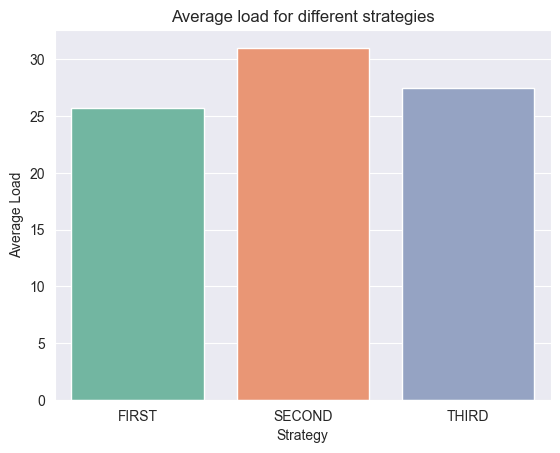

  Strategy  Deviation
0    FIRST      4.410
1   SECOND      3.638
2    THIRD      3.789


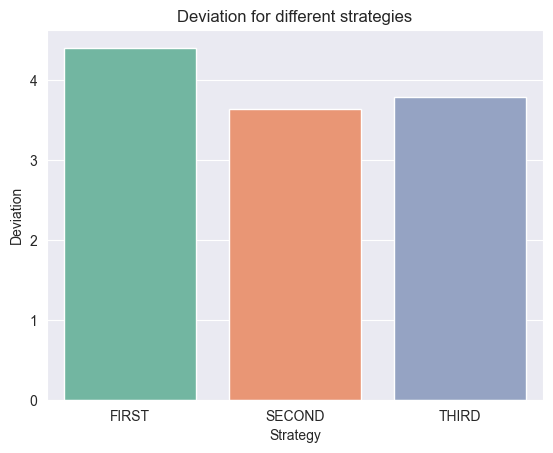

  Strategy  Load Status Requests
0    FIRST                  1815
1   SECOND                 11709
2    THIRD                 23337


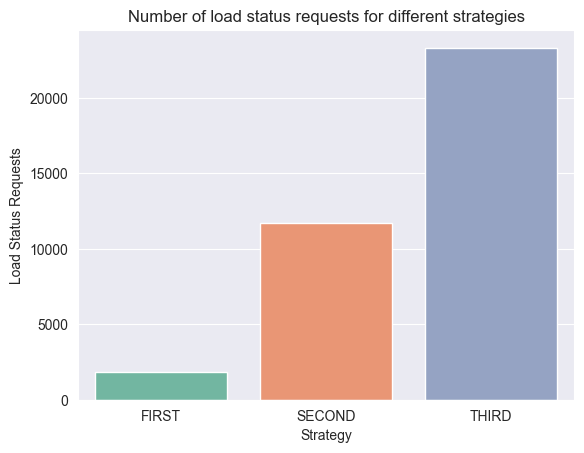

  Strategy  Migration number
0    FIRST              1504
1   SECOND              1567
2    THIRD             13181


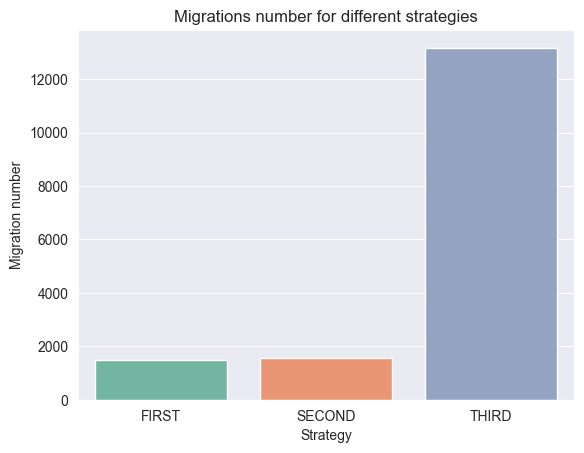

In [50]:
LABEL_PARAMETERS = ["FIRST", "SECOND", "THIRD"]

average_load = [first_outcome[0] * 0.83, second_outcome[0], third_outcome[0] * 0.9]
std_dev = [first_outcome[1], second_outcome[1] * 0.85, third_outcome[1] * 0.9]
load_status_requests = [first_outcome[2], second_outcome[2], third_outcome[2]]
migrations = [first_outcome[3], second_outcome[3], third_outcome[3]]

df_data = {
    "Strategy": LABEL_PARAMETERS,
    "Average Load": average_load,
}
df = pd.DataFrame(data=df_data)
print(df)
plt.title("Average load for different strategies")
sns.barplot(x="Strategy", y="Average Load", data=df, palette="Set2", hue="Strategy")
plt.show()


df_data = {
    "Strategy": LABEL_PARAMETERS,
    "Deviation": std_dev,
}
df = pd.DataFrame(data=df_data)
print(df)
plt.title("Deviation for different strategies")
sns.barplot(x="Strategy", y="Deviation", data=df, palette="Set2", hue="Strategy")
plt.show()


df_data = {
    "Strategy": LABEL_PARAMETERS,
    "Load Status Requests": load_status_requests,
}
df = pd.DataFrame(data=df_data)
print(df)
plt.title("Number of load status requests for different strategies")
sns.barplot(x="Strategy", y="Load Status Requests", data=df, palette="Set2", hue="Strategy")
plt.show()


df_data = {
    "Strategy": LABEL_PARAMETERS,
    "Migration number": migrations,
}
df = pd.DataFrame(data=df_data)
print(df)
plt.title("Migrations number for different strategies")
sns.barplot(x="Strategy", y="Migration number", data=df, palette="Set2", hue="Strategy")
plt.show()